In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Task 2

In [2]:
data_df=pd.read_csv("Social_media_impact_on_life.csv")
data=data_df.copy()

In [3]:
data_df.info

<bound method DataFrame.info of        Student_ID  Age  Gender Academic_Level Primary_Platform  \
0     STU_2024000   19  Female  Undergraduate         Snapchat   
1     STU_2024001   19  Female  Undergraduate        Instagram   
2     STU_2024002   17  Female    High School           TikTok   
3     STU_2024003   16  Female    High School          YouTube   
4     STU_2024004   17    Male    High School         LinkedIn   
...           ...  ...     ...            ...              ...   
4495  STU_2028495   16    Male    High School          YouTube   
4496  STU_2028496   19  Female  Undergraduate         LinkedIn   
4497  STU_2028497   19    Male  Undergraduate        Instagram   
4498  STU_2028498   16    Male    High School         LinkedIn   
4499  STU_2028499   24    Male  Undergraduate        Instagram   

      Daily_Usage_Hours  Weekend_Extra_Hours Device_Type  \
0                   7.5                  1.5  Smartphone   
1                   4.6                  1.3  Smartphon

In [4]:
data_df.shape

(4500, 16)

In [5]:
data_df.describe()

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


In [6]:

data_df.describe(include='all')


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
count,4500,4500.000000,4500,4500,4500,4500.000000,4500.000000,4500,4500.000000,4500.000000,4500,4500,4454.000000,4500.000000,4415.000000,4500
unique,4500,NaN,4,3,7,NaN,NaN,3,NaN,NaN,2,5,NaN,NaN,NaN,3
top,STU_2028499,NaN,Female,Undergraduate,Instagram,NaN,NaN,Smartphone,NaN,NaN,True,Sometimes,NaN,NaN,NaN,Beneficial
freq,1,NaN,2234,2777,1453,NaN,NaN,3775,NaN,NaN,2644,1594,NaN,NaN,NaN,3681
mean,NaN,18.703333,NaN,NaN,NaN,5.295933,1.796844,NaN,6.701333,2.472000,NaN,NaN,13.512124,79.873111,3.429282,NaN
std,NaN,1.981182,NaN,NaN,NaN,2.604497,0.699245,NaN,1.189998,1.030484,NaN,NaN,7.072859,12.876044,0.392662,NaN
min,NaN,15.000000,NaN,NaN,NaN,0.900000,0.000000,NaN,3.000000,1.000000,NaN,NaN,0.000000,32.000000,1.900000,NaN
25%,NaN,17.000000,NaN,NaN,NaN,3.400000,1.300000,NaN,6.000000,2.000000,NaN,NaN,9.000000,72.000000,3.200000,NaN
50%,NaN,19.000000,NaN,NaN,NaN,4.700000,1.800000,NaN,6.800000,3.000000,NaN,NaN,13.000000,82.000000,3.460000,NaN
75%,NaN,20.000000,NaN,NaN,NaN,6.600000,2.300000,NaN,7.500000,3.000000,NaN,NaN,18.000000,89.000000,3.720000,NaN


In [7]:
data_df.columns.to_list()

['Student_ID',
 'Age',
 'Gender',
 'Academic_Level',
 'Primary_Platform',
 'Daily_Usage_Hours',
 'Weekend_Extra_Hours',
 'Device_Type',
 'Sleep_Duration_Hours',
 'Sleep_Quality_Score',
 'Late_Night_Usage',
 'Social_Comparison_Frequency',
 'Perceived_Stress_Score',
 'Mental_Health_Index',
 'Academic_Performance_GPA',
 'Overall_Impact']

In [8]:
print(data_df.duplicated().sum())

0


In [9]:
print(data_df['Overall_Impact'].value_counts())

Overall_Impact
Beneficial    3681
Neutral        654
Negative       165
Name: count, dtype: int64


In [10]:
print(data_df['Overall_Impact'].value_counts(normalize=True) * 100)

Overall_Impact
Beneficial    81.800000
Neutral       14.533333
Negative       3.666667
Name: proportion, dtype: float64


## Task:3

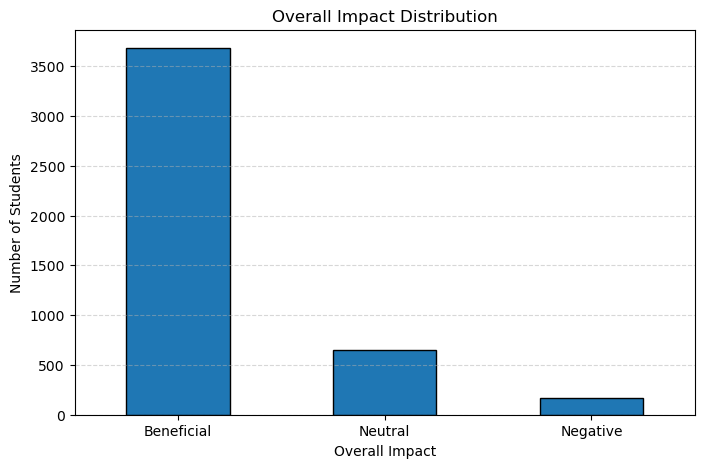

In [11]:
plt.figure(figsize=(8, 5))

data_df['Overall_Impact'].value_counts().plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Overall Impact Distribution')
plt.xlabel('Overall Impact')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

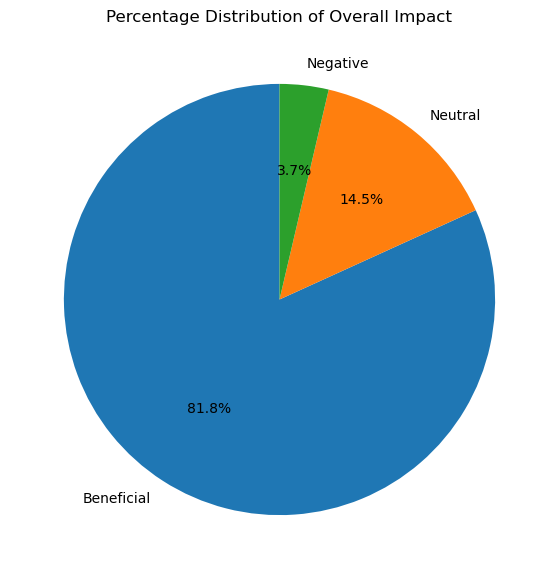

In [12]:
plt.figure(figsize=(7, 7))

data_df['Overall_Impact'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Distribution of Overall Impact')
plt.ylabel('')

plt.show()

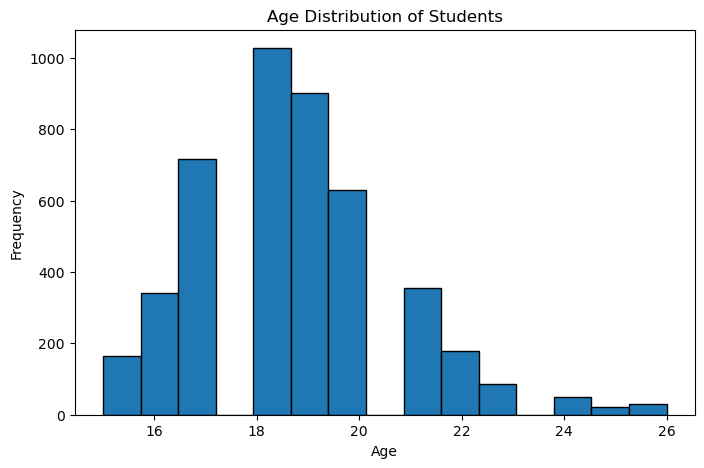

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(data_df['Age'], bins=15, edgecolor='black')

plt.title('Age Distribution of Students')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

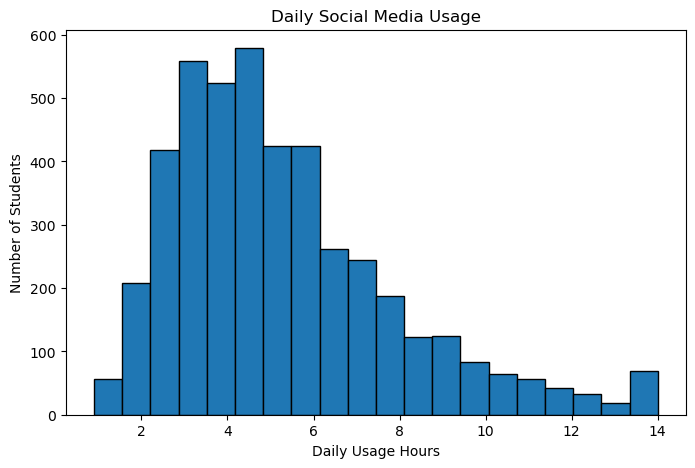

In [14]:
plt.figure(figsize=(8, 5))

plt.hist(data_df['Daily_Usage_Hours'], bins=20, edgecolor='black')

plt.title('Daily Social Media Usage')
plt.xlabel('Daily Usage Hours')
plt.ylabel('Number of Students')

plt.show()

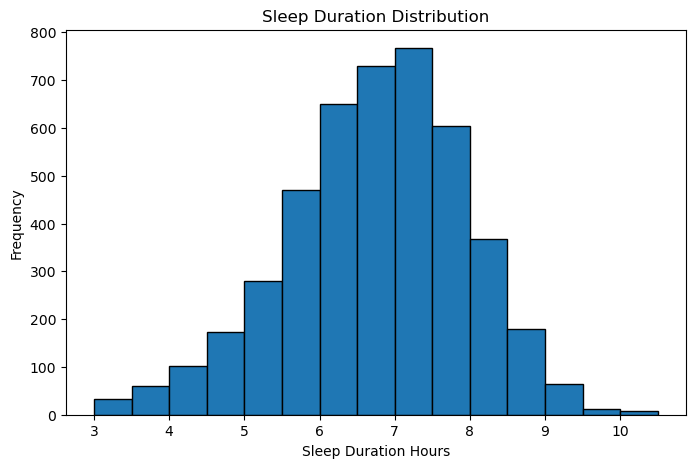

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(data_df['Sleep_Duration_Hours'], bins=15, edgecolor='black')

plt.title('Sleep Duration Distribution')
plt.xlabel('Sleep Duration Hours')
plt.ylabel('Frequency')

plt.show()

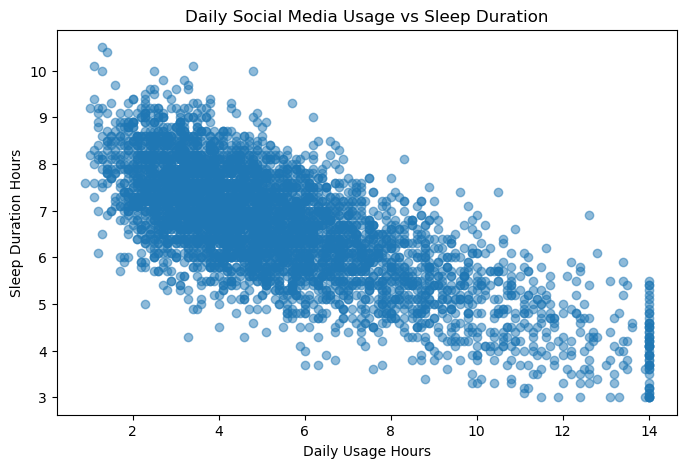

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data_df['Daily_Usage_Hours'],
    data_df['Sleep_Duration_Hours'],
    alpha=0.5
)

plt.title('Daily Social Media Usage vs Sleep Duration')
plt.xlabel('Daily Usage Hours')
plt.ylabel('Sleep Duration Hours')

plt.show()

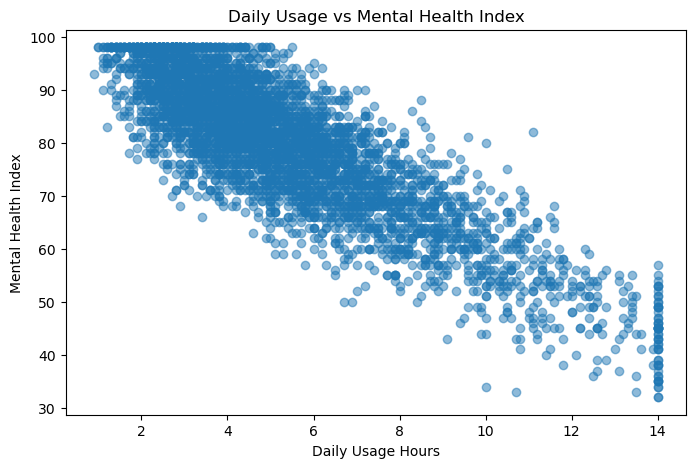

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data_df['Daily_Usage_Hours'],
    data_df['Mental_Health_Index'],
    alpha=0.5
)

plt.title('Daily Usage vs Mental Health Index')
plt.xlabel('Daily Usage Hours')
plt.ylabel('Mental Health Index')

plt.show()

## Task:4

In [18]:
print("Missing Values Before Cleaning:")
print(data_df.isnull().sum())

print("\nTotal Missing Values:")
print(data_df.isnull().sum().sum())

Missing Values Before Cleaning:
Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64

Total Missing Values:
131


In [19]:
data_df = data_df.drop(columns=['Student_ID'])

print("Student_ID Column Removed Successfully!")
print("New Dataset Shape:", data_df.shape)

Student_ID Column Removed Successfully!
New Dataset Shape: (4500, 15)


In [20]:
data_df['Perceived_Stress_Score'] = data_df['Perceived_Stress_Score'].fillna(
    data_df['Perceived_Stress_Score'].median()
)

data_df['Academic_Performance_GPA'] = data_df['Academic_Performance_GPA'].fillna(
    data_df['Academic_Performance_GPA'].median()
)

print("Missing Values Filled Successfully!")

Missing Values Filled Successfully!


In [21]:
print("Missing Values After Cleaning:")
print(data_df.isnull().sum())

print("\nTotal Missing Values:")
print(data_df.isnull().sum().sum())

Missing Values After Cleaning:
Age                            0
Gender                         0
Academic_Level                 0
Primary_Platform               0
Daily_Usage_Hours              0
Weekend_Extra_Hours            0
Device_Type                    0
Sleep_Duration_Hours           0
Sleep_Quality_Score            0
Late_Night_Usage               0
Social_Comparison_Frequency    0
Perceived_Stress_Score         0
Mental_Health_Index            0
Academic_Performance_GPA       0
Overall_Impact                 0
dtype: int64

Total Missing Values:
0


In [22]:
print("Dataset Shape:", data_df.shape)

data_df.info()

Dataset Shape: (4500, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 15 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Age                          4500 non-null   int64  
 1   Gender                       4500 non-null   object 
 2   Academic_Level               4500 non-null   object 
 3   Primary_Platform             4500 non-null   object 
 4   Daily_Usage_Hours            4500 non-null   float64
 5   Weekend_Extra_Hours          4500 non-null   float64
 6   Device_Type                  4500 non-null   object 
 7   Sleep_Duration_Hours         4500 non-null   float64
 8   Sleep_Quality_Score          4500 non-null   int64  
 9   Late_Night_Usage             4500 non-null   bool   
 10  Social_Comparison_Frequency  4500 non-null   object 
 11  Perceived_Stress_Score       4500 non-null   float64
 12  Mental_Health_Index          4500 non-null   int64

### Data clean completed

## Task:5

In [23]:
X = data_df.drop(columns=['Overall_Impact'])

y = data_df['Overall_Impact']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (4500, 14)
Target Shape: (4500,)


In [24]:
numeric_columns = X.select_dtypes(include=np.number).columns.tolist()

categorical_columns = X.select_dtypes(
    include=['object', 'bool', 'category']
).columns.tolist()

print("Numerical Columns:")
print(numeric_columns)

print("\nCategorical Columns:")
print(categorical_columns)

print("\nTotal Numerical Columns:", len(numeric_columns))
print("Total Categorical Columns:", len(categorical_columns))

Numerical Columns:
['Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index', 'Academic_Performance_GPA']

Categorical Columns:
['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type', 'Late_Night_Usage', 'Social_Comparison_Frequency']

Total Numerical Columns: 8
Total Categorical Columns: 6


### Train - Split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (3600, 14)
Testing Data Shape: (900, 14)

Training Target Distribution:
Overall_Impact
Beneficial    2945
Neutral        523
Negative       132
Name: count, dtype: int64

Testing Target Distribution:
Overall_Impact
Beneficial    736
Neutral       131
Negative       33
Name: count, dtype: int64


## Data Preprocessing

## `Create Numerical Pipeline

In [26]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

### Create Categorical Pipeline

In [27]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

### Combine Both Pipelines

In [28]:
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_columns),
    ('cat', categorical_transformer, categorical_columns)
])

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


### Apply Preprocessing

In [29]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Data Shape After Preprocessing:",
      X_train_processed.shape)

print("Testing Data Shape After Preprocessing:",
      X_test_processed.shape)

Training Data Shape After Preprocessing: (3600, 32)
Testing Data Shape After Preprocessing: (900, 32)


## Import Models and Evaluation Metrics

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All Models and Metrics Imported Successfully!")

All Models and Metrics Imported Successfully!


## Create Three Models

In [31]:
model_1 = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

model_2 = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42
)

model_3 = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

print("Three Machine Learning Models Created Successfully!")

Three Machine Learning Models Created Successfully!


# Train First Model

In [32]:
model_1.fit(X_train_processed, y_train)

print("Logistic Regression Training Completed!")

Logistic Regression Training Completed!


# Train Second Model

In [33]:
model_2.fit(X_train_processed, y_train)

print("Random Forest Training Completed!")

Random Forest Training Completed!


# Train Third Model

In [34]:
model_3.fit(X_train_processed, y_train)

print("Gradient Boosting Training Completed!")

Gradient Boosting Training Completed!


# Make Predictions

In [35]:
prediction_1 = model_1.predict(X_test_processed)
prediction_2 = model_2.predict(X_test_processed)
prediction_3 = model_3.predict(X_test_processed)

print("Predictions Completed Successfully!")

Predictions Completed Successfully!


# Calculate Model Performance

In [36]:
models = ['Logistic Regression', 'Random Forest', 'Gradient Boosting']

predictions = [prediction_1, prediction_2, prediction_3]

accuracy_values = []
precision_values = []
recall_values = []
f1_values = []

for prediction in predictions:

    accuracy_values.append(
        accuracy_score(y_test, prediction) * 100
    )

    precision_values.append(
        precision_score(y_test, prediction, average='macro', zero_division=0) * 100
    )

    recall_values.append(
        recall_score(y_test, prediction, average='macro', zero_division=0) * 100
    )

    f1_values.append(
        f1_score(y_test, prediction, average='macro', zero_division=0) * 100
    )

print("All Model Evaluation Scores Calculated!")

All Model Evaluation Scores Calculated!


# Create Comparison Table

In [37]:
comparison_df = pd.DataFrame({
    'Model': models,
    'Accuracy (%)': accuracy_values,
    'Precision (%)': precision_values,
    'Recall (%)': recall_values,
    'Macro F1-Score (%)': f1_values
})

comparison_df = comparison_df.sort_values(
    by='Macro F1-Score (%)',
    ascending=False
)

print(comparison_df.to_string(index=False))

              Model  Accuracy (%)  Precision (%)  Recall (%)  Macro F1-Score (%)
  Gradient Boosting     97.333333      93.348246   93.717816           93.531231
Logistic Regression     97.000000      90.896705   96.139058           93.365715
      Random Forest     96.666667      93.861894   90.052313           91.872378


## Compare Model Accuracy

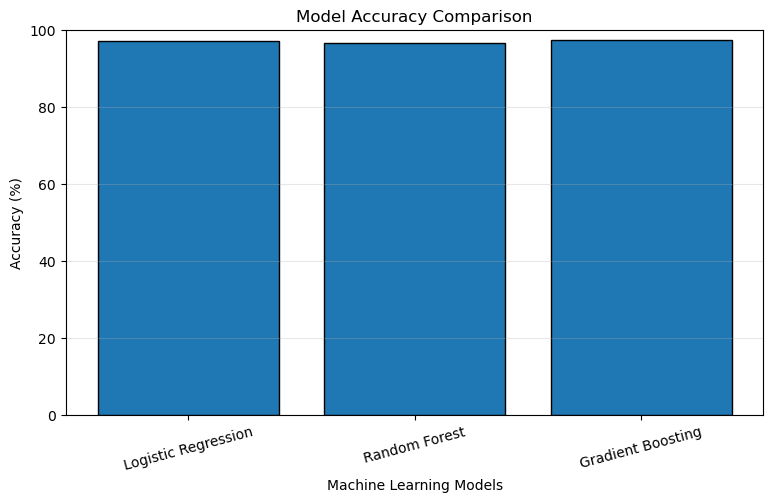

In [38]:
plt.figure(figsize=(9, 5))

plt.bar(models, accuracy_values, edgecolor='black')

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

plt.show()

## Compare Macro F1-Scores

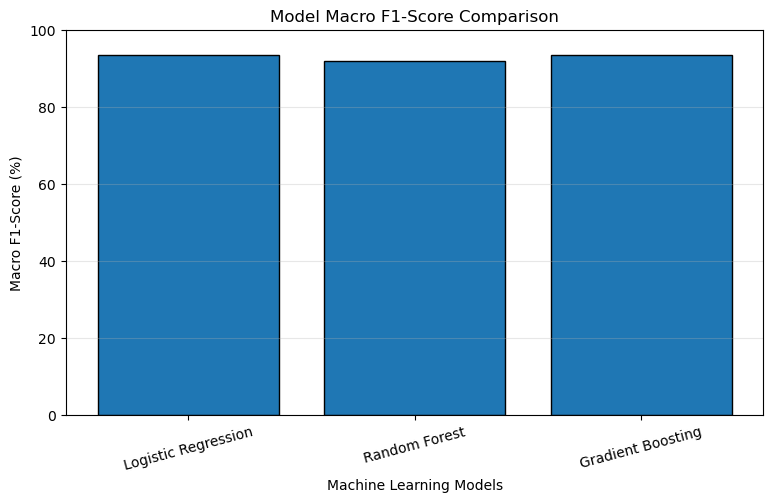

In [39]:
plt.figure(figsize=(9, 5))

plt.bar(models, f1_values, edgecolor='black')

plt.title('Model Macro F1-Score Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Macro F1-Score (%)')
plt.xticks(rotation=15)
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

plt.show()

# Select Best Model

In [40]:
best_model_name = comparison_df.iloc[0]['Model']

print("Best Model:", best_model_name)

print(
    "Best Macro F1-Score:",
    round(comparison_df.iloc[0]['Macro F1-Score (%)'], 2),
    "%"
)

Best Model: Gradient Boosting
Best Macro F1-Score: 93.53 %


# Best Model Evaluation

#### Classification Report

In [41]:
best_model = model_3

print("Gradient Boosting Classification Report:\n")

print(classification_report(
    y_test,
    prediction_3,
    zero_division=0
))

Gradient Boosting Classification Report:

              precision    recall  f1-score   support

  Beneficial       0.99      0.99      0.99       736
    Negative       0.91      0.91      0.91        33
     Neutral       0.90      0.92      0.91       131

    accuracy                           0.97       900
   macro avg       0.93      0.94      0.94       900
weighted avg       0.97      0.97      0.97       900



#### Confusion Matrix

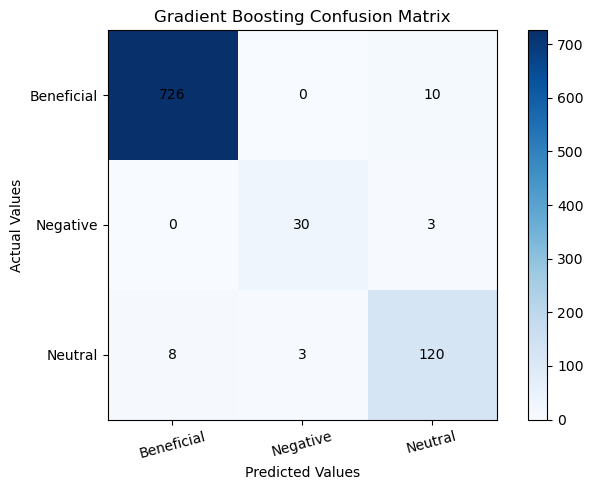

In [42]:
cm = confusion_matrix(y_test, prediction_3)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap='Blues')
plt.colorbar()

plt.xticks(range(len(best_model.classes_)), best_model.classes_, rotation=15)
plt.yticks(range(len(best_model.classes_)), best_model.classes_)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Gradient Boosting Confusion Matrix")

for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.tight_layout()
plt.show()

### Training vs Testing Performance

In [43]:
train_prediction = best_model.predict(X_train_processed)
test_prediction = best_model.predict(X_test_processed)

train_f1 = f1_score(
    y_train, train_prediction, average='macro'
)

test_f1 = f1_score(
    y_test, test_prediction, average='macro'
)

print("Training Macro F1-Score:", round(train_f1 * 100, 2), "%")
print("Testing Macro F1-Score:", round(test_f1 * 100, 2), "%")

print("Performance Difference:",
      round((train_f1 - test_f1) * 100, 2), "%")

Training Macro F1-Score: 99.96 %
Testing Macro F1-Score: 93.53 %
Performance Difference: 6.43 %


#### Compare Training and Testing Scores

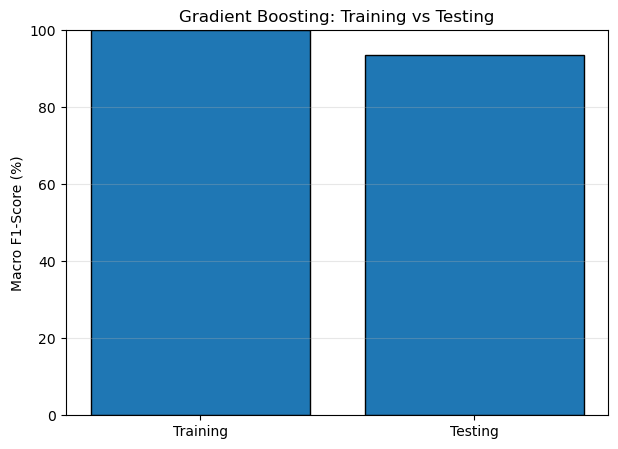

In [44]:
plt.figure(figsize=(7, 5))

plt.bar(
    ['Training', 'Testing'],
    [train_f1 * 100, test_f1 * 100],
    edgecolor='black'
)

plt.title('Gradient Boosting: Training vs Testing')
plt.ylabel('Macro F1-Score (%)')
plt.ylim(0, 100)
plt.grid(axis='y', alpha=0.3)

plt.show()

# Cross-Validation

#### Import Cross-Validation

In [45]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

### Create Cross-Validation

In [46]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Cross Validation Created!")

5-Fold Cross Validation Created!


### Evaluate Gradient Boosting

In [47]:
cv_scores = cross_val_score(
    best_model,
    X_train_processed,
    y_train,
    cv=cv,
    scoring='f1_macro'
)

print("Cross Validation Scores:")

for i, score in enumerate(cv_scores):
    print(f"Fold {i+1}: {score * 100:.2f}%")

print("\nAverage CV Score:", round(cv_scores.mean() * 100, 2), "%")
print("Standard Deviation:", round(cv_scores.std() * 100, 2), "%")

Cross Validation Scores:
Fold 1: 92.83%
Fold 2: 96.12%
Fold 3: 97.24%
Fold 4: 94.48%
Fold 5: 91.19%

Average CV Score: 94.37 %
Standard Deviation: 2.18 %


# Proper Cross-Validation and Model Comparison

### Create Three Complete Pipelines

In [48]:
from sklearn.base import clone

pipeline_1 = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

pipeline_2 = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42
    ))
])

pipeline_3 = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ))
])

print("All Three Complete Pipelines Created!")

All Three Complete Pipelines Created!


### Cross-Validate All Three Models

In [49]:
model_pipelines = {
    'Logistic Regression': pipeline_1,
    'Random Forest': pipeline_2,
    'Gradient Boosting': pipeline_3
}

cv_results = {}

for model_name, model_pipeline in model_pipelines.items():

    scores = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='f1_macro',
        n_jobs=-1
    )

    cv_results[model_name] = scores

    print("\nModel:", model_name)
    print("Fold Scores:", np.round(scores * 100, 2))
    print("Average Score:", round(scores.mean() * 100, 2), "%")


Model: Logistic Regression
Fold Scores: [93.22 94.37 92.35 93.95 91.27]
Average Score: 93.03 %

Model: Random Forest
Fold Scores: [92.06 95.26 89.85 89.57 88.48]
Average Score: 91.05 %

Model: Gradient Boosting
Fold Scores: [92.83 96.12 97.24 94.48 91.19]
Average Score: 94.37 %


### Create Final Comparison Table

In [50]:
final_comparison = pd.DataFrame({
    'Model': list(cv_results.keys()),
    'Average CV F1 (%)': [
        scores.mean() * 100
        for scores in cv_results.values()
    ],
    'Standard Deviation (%)': [
        scores.std() * 100
        for scores in cv_results.values()
    ]
})

final_comparison = final_comparison.sort_values(
    by='Average CV F1 (%)',
    ascending=False
).reset_index(drop=True)

print(final_comparison.to_string(index=False))

              Model  Average CV F1 (%)  Standard Deviation (%)
  Gradient Boosting          94.372192                2.181690
Logistic Regression          93.032578                1.116188
      Random Forest          91.046392                2.408415


### Select Best Model Based on Cross-Validation

In [51]:
best_model_name = final_comparison.iloc[0]['Model']

best_pipeline = model_pipelines[best_model_name]

print("Selected Model:", best_model_name)

print(
    "Average CV Macro F1:",
    round(final_comparison.iloc[0]['Average CV F1 (%)'], 2),
    "%"
)

Selected Model: Gradient Boosting
Average CV Macro F1: 94.37 %


# Train the final model

In [52]:
# Train the best model

best_pipeline.fit(X_train, y_train)

print("Final model training completed successfully!")

Final model training completed successfully!


# Final Model Evaluation

In [53]:
# Make predictions on test data

final_predictions = best_pipeline.predict(X_test)

# Calculate performance
final_accuracy = accuracy_score(y_test, final_predictions)
final_f1 = f1_score(y_test, final_predictions, average='macro')

print("Final Model Performance")
print("-----------------------")
print("Accuracy:", round(final_accuracy * 100, 2), "%")
print("Macro F1-Score:", round(final_f1 * 100, 2), "%")

Final Model Performance
-----------------------
Accuracy: 97.33 %
Macro F1-Score: 93.53 %


# Classification Report

In [54]:
# Classification Report

print("Classification Report")
print("---------------------")

print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

Classification Report
---------------------
              precision    recall  f1-score   support

  Beneficial       0.99      0.99      0.99       736
    Negative       0.91      0.91      0.91        33
     Neutral       0.90      0.92      0.91       131

    accuracy                           0.97       900
   macro avg       0.93      0.94      0.94       900
weighted avg       0.97      0.97      0.97       900



# Confusion Matrix

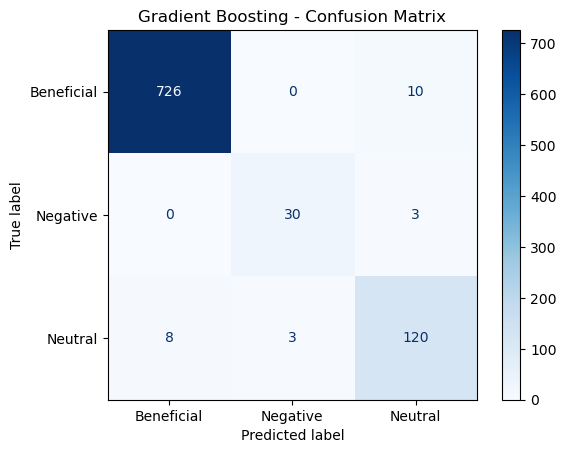

In [55]:
# Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    cmap='Blues'
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.show()